In [77]:
import pandas as pd
import numpy as np

import scipy.stats as stats

import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score
from sklearn.model_selection import cross_val_score

from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier

from sklearn.preprocessing import FunctionTransformer
from sklearn.compose import ColumnTransformer

In [78]:
df = pd.read_csv('train.csv', usecols = ['Age', 'Fare', 'Survived'])

In [79]:
df.head()

,Survived,Age,Fare
0,0,22.0,7.2500
1,1,38.0,71.2833
2,1,26.0,7.9250
3,1,35.0,53.1000
4,0,35.0,8.0500


In [80]:
df.isnull().sum()

Survived      0
Age         177
Fare          0
dtype: int64

In [81]:
# to fill the missig value use fillna() function
df.fillna({'Age': df['Age'].mean()}, inplace=True)

,Survived,Age,Fare
0,0,22.000000,7.2500
1,1,38.000000,71.2833
2,1,26.000000,7.9250
3,1,35.000000,53.1000
4,0,35.000000,8.0500
...,...,...,...
886,0,27.000000,13.0000
887,1,19.000000,30.0000
888,0,29.699118,23.4500
889,1,26.000000,30.0000


In [82]:
df.head()

,Survived,Age,Fare
0,0,22.0,7.2500
1,1,38.0,71.2833
2,1,26.0,7.9250
3,1,35.0,53.1000
4,0,35.0,8.0500


In [83]:
X = df.iloc[:, 1:3] # 1:3 means from column 1 to 3
y = df.iloc[:, 0] # 0 means 0 will be output column

In [84]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

Text(0.5, 1.0, 'Age QQ Plot')

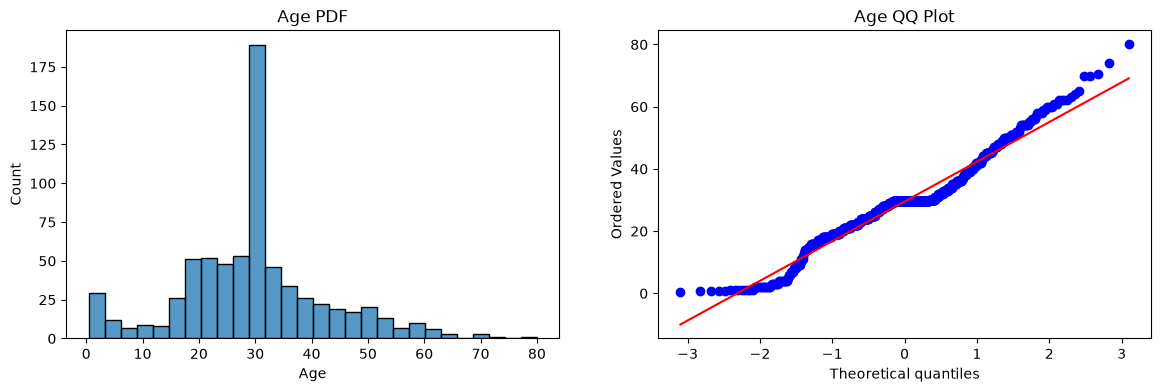

In [85]:
# Create a wide figure to fit 2 plots side by side
plt.figure(figsize=(14,4))

# 1 row, 2 columns, select the 1st (left) plot
plt.subplot(121)

# Show the distribution of Age
sns.histplot(X_train['Age'])

# Add title to the left plot
plt.title('Age PDF')

# 1 row, 2 columns, select the 2nd (right) plot
plt.subplot(122)

# Compare Age data with a normal distribution using a QQ plot
#Take my Age data, compare it with a normal distribution, and draw the comparison using Matplotlib.
stats.probplot(X_train['Age'], dist='norm', plot=plt)

# Add title to the right plot
plt.title('Age QQ Plot')

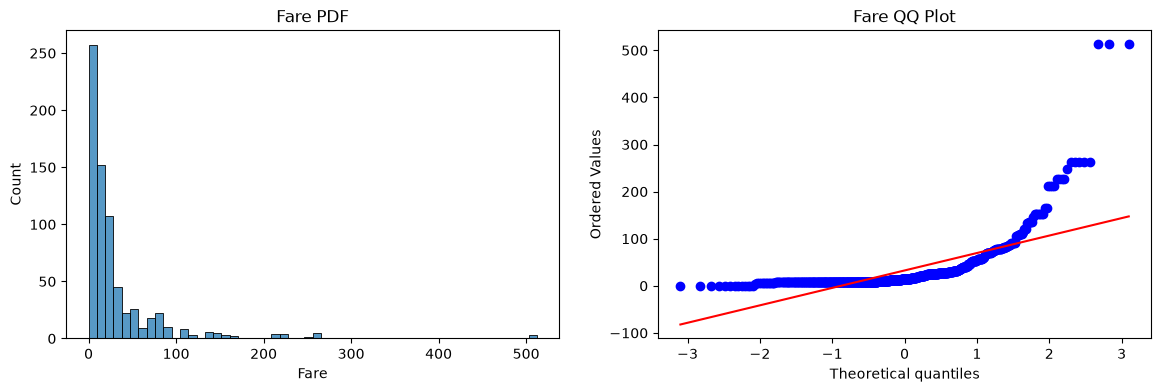

In [86]:
plt.figure(figsize= (14,4))

plt.subplot(121)
sns.histplot(X_train['Fare'])
plt.title('Fare PDF')

plt.subplot(122)
stats.probplot(X_train['Fare'], dist = 'norm', plot=plt)
plt.title('Fare QQ Plot')

plt.show()
# o/p will show it's right skewed so we use LOG TRANSFORM

In [87]:
# creating objecsts 
clf = LogisticRegression()
clf2 = DecisionTreeClassifier()

In [88]:
clf.fit(X_train, y_train)
clf2.fit(X_train, y_train)

y_pred = clf.predict(X_test)
y_pred1 = clf2.predict(X_test)

print('Accuracy LR', accuracy_score(y_test, y_pred))
print('Accuracy DT', accuracy_score(y_test, y_pred1))


Accuracy LR 0.6480446927374302
Accuracy DT 0.6759776536312849


### APPLYING LOG TRANSFORM

In [89]:
# NOW WE APPLY LOG TRANSFORM
# Create a transformer that applies log(1 + x) to the data
trf = FunctionTransformer(func=np.log1p)

In [90]:
X_train_transformed = trf.fit_transform(X_train)
# for test dat ause only transform
X_test_transformed = trf.transform(X_test)

In [91]:
clf = LogisticRegression()
clf2 = DecisionTreeClassifier()

# we train them . This is where the models learn patterns from our training data.
clf.fit(X_train_transformed, y_train)
clf2.fit(X_train_transformed, y_train)

#Now we test what they learned
y_pred = clf.predict(X_test_transformed)
y_pred1 = clf2.predict(X_test_transformed)


print('Accuracy LR', accuracy_score(y_test, y_pred))
print('Accuracy DT', accuracy_score(y_test, y_pred1))


Accuracy LR 0.6815642458100558
Accuracy DT 0.6759776536312849


# we check accuracy using Cross Validation

In [92]:
X_transformed = trf.fit_transform(X)
X_transformed

,Age,Fare
0,3.135494,2.110213
1,3.663562,4.280593
2,3.295837,2.188856
3,3.583519,3.990834
4,3.583519,2.202765
...,...,...
886,3.332205,2.639057
887,2.995732,3.433987
888,3.424234,3.196630
889,3.295837,3.433987


In [93]:
clf = LogisticRegression()
clf1 = DecisionTreeClassifier()

#Train and test the Logistic Regression model 10 different times using cross-validation, and get the accuracy for each time.
print('LR', np.mean(cross_val_score(clf,X_transformed, y, scoring= 'accuracy', cv=10)))
print('DT', np.mean(cross_val_score(clf2, X_transformed, y, scoring = 'accuracy', cv=10)))

LR 0.678027465667915
DT 0.6566167290886392


Text(0.5, 1.0, 'Fare After Log')

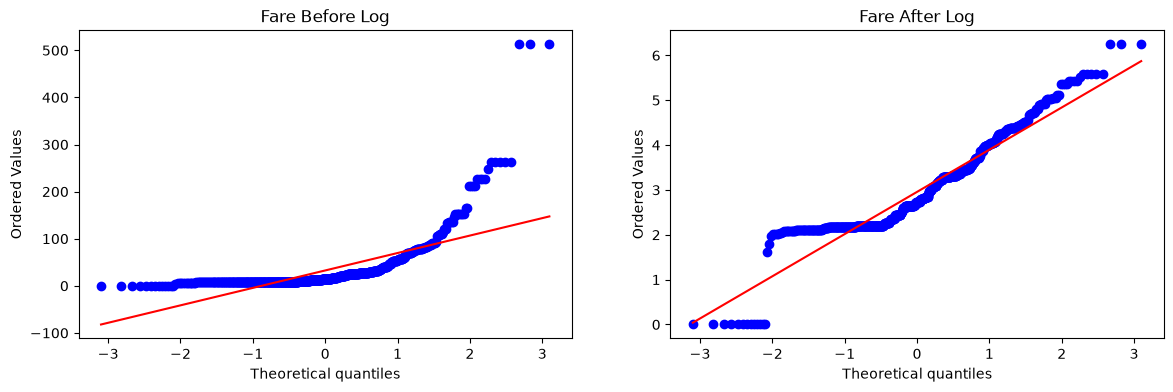

In [94]:
plt.figure(figsize=(14,4))

plt.subplot(121)
stats.probplot(X_train['Fare'], dist = 'norm', plot=plt)
plt.title('Fare Before Log')

plt.subplot(122)
stats.probplot(X_train_transform['Fare'], dist='norm', plot=plt)
plt.title('Fare After Log')

Text(0.5, 1.0, 'Age After Log')

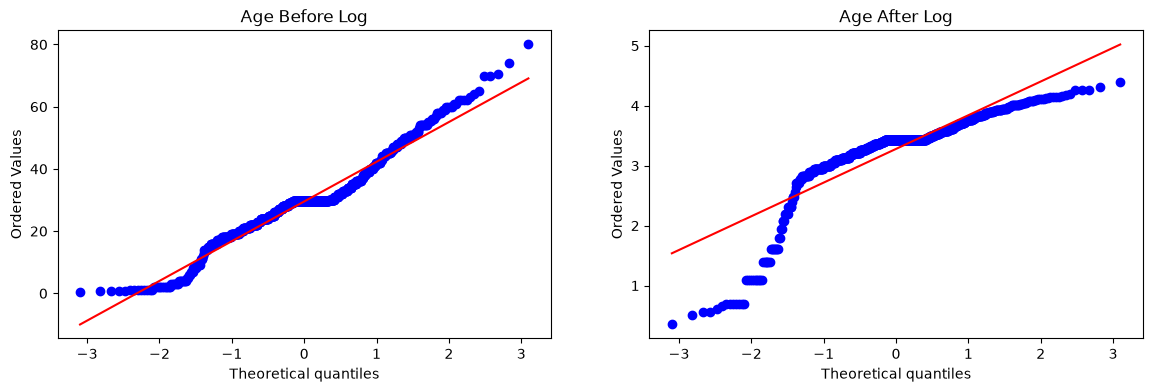

In [95]:
plt.figure(figsize=(14,4))

plt.subplot(121)
stats.probplot(X_train['Age'], dist = 'norm', plot=plt)
plt.title('Age Before Log')

plt.subplot(122)
stats.probplot(X_train_transform['Age'], dist='norm', plot=plt)
plt.title('Age After Log')

# for age before looks good because it was nt right skewed and we forcefuly applied log trasformer

### Rather than applying Log Transform on both (Age and Fare). Let's apply log transform only on log and leave Age

In [96]:
# Create a ColumnTransformer to apply different transformations to different columns.
# Here, we apply a log transformation only to the 'Fare' column.
# FunctionTransformer(np.log1p) applies log(1 + x) to the Fare values.
# 'log' is simply the name we give to this transformation.
# ['Fare'] tells the ColumnTransformer which column should receive the log transformation.
# remainder='passthrough' means all other columns are kept unchanged.

trf2 = ColumnTransformer([
    ('log', FunctionTransformer(np.log1p), ['Fare'])
], remainder='passthrough')

In [97]:
X_train_transformed2 = trf2.fit_transform(X_train)
X_test_transformed2 = trf2.transform(X_test)

In [100]:
clf = LogisticRegression()
clf2 = DecisionTreeClassifier()

clf.fit(X_train_transformed2, y_train)
clf2.fit(X_train_transformed2, y_train)

y_pred = clf.predict(X_test_transformed2)
y_pred2 = clf2.predict(X_test_transformed2)

print('Accuracy LR', accuracy_score(y_test, y_pred))
print('Accuracy DT', accuracy_score(y_test, y_pred2))

Accuracy LR 0.6703910614525139
Accuracy DT 0.659217877094972


In [102]:
# we use cross value score on these data
X_transformed2 = trf2.fit_transform(X)

clf = LogisticRegression()
clf2 = DecisionTreeClassifier()

print('LR', np.mean(cross_val_score(clf, X_transformed2, y, scoring = 'accuracy', cv=10)))
print('DR', np.mean(cross_val_score(clf2, X_transformed2, y, scoring = 'accuracy', cv=10)))


LR 0.6712609238451936
DR 0.6566042446941323


####  trf → applies log transformation to all columns
#### trf2 → applies log transformation only to the Fare column and keeps other columns unchanged

#### Decision Tree does not care much about whether the data is normally distributed or log-transformed,so the accuracy may remain almost the same after applying the log transformation. but on linear/logistic regression the result is improved with our transformation

In [104]:
df

,Survived,Age,Fare
0,0,22.000000,7.2500
1,1,38.000000,71.2833
2,1,26.000000,7.9250
3,1,35.000000,53.1000
4,0,35.000000,8.0500
...,...,...,...
886,0,27.000000,13.0000
887,1,19.000000,30.0000
888,0,29.699118,23.4500
889,1,26.000000,30.0000


### HERE WE USE OTHER TRANSFORM

In [126]:
# Create a function named apply_transform
# 'transform' is the input/placeholder that we will pass to the function
def apply_transform(transform):
    X = df.iloc[:,1:3]
    y= df.iloc[:, 0]    
    trf = ColumnTransformer([('log',
                         FunctionTransformer(transform),
                             ['Fare'])],
                           remainder = 'passthrough')

    X_trans = trf.fit_transform(X)
    clf = LogisticRegression()

    print('Accuracy', np.mean(cross_val_score(clf, X_trans, y, scoring='accuracy', cv=10)))
    plt.figure(figsize=(14,4))

    plt.subplot(121)
    stats.probplot(X['Fare'], dist="norm", plot=plt)
    plt.title('Fare Before Transform')

    plt.subplot(122)
    stats.probplot(X_trans[:,0], dist="norm", plot=plt)
    plt.title('Fare After Transform')

    plt.show()
    


Accuracy 0.6589013732833957


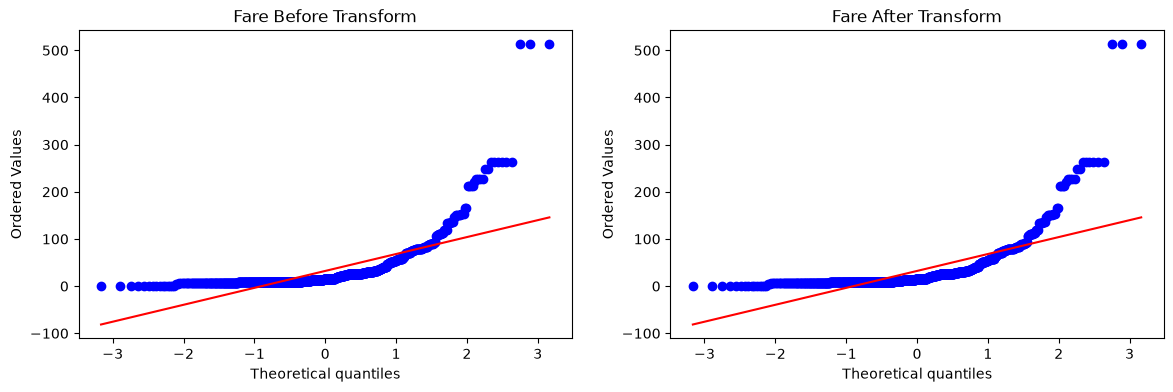

In [127]:
apply_transform(lambda x: x)

Accuracy 0.6431335830212235


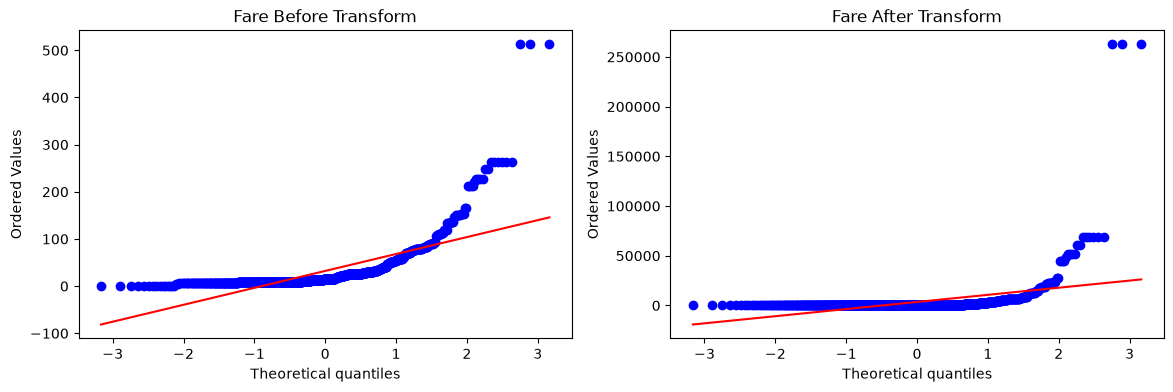

In [128]:
apply_transform(lambda x: x**2)

Accuracy 0.6262796504369538


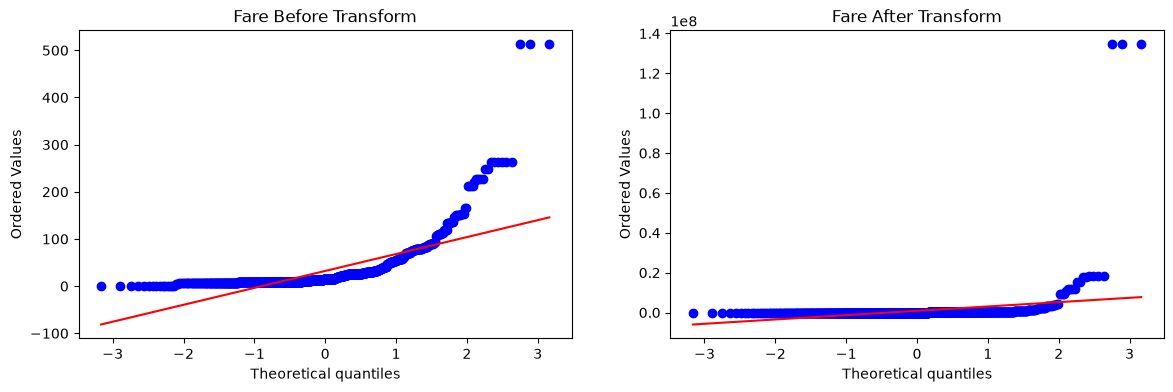

In [129]:
apply_transform(lambda x: x**3)

Accuracy 0.6589013732833957


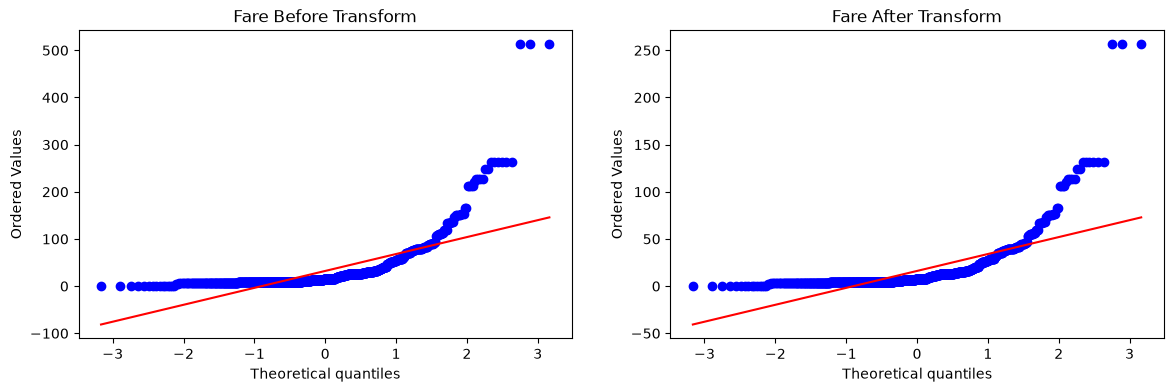

In [130]:
apply_transform(lambda x: x**1/2)

Accuracy 0.616167290886392


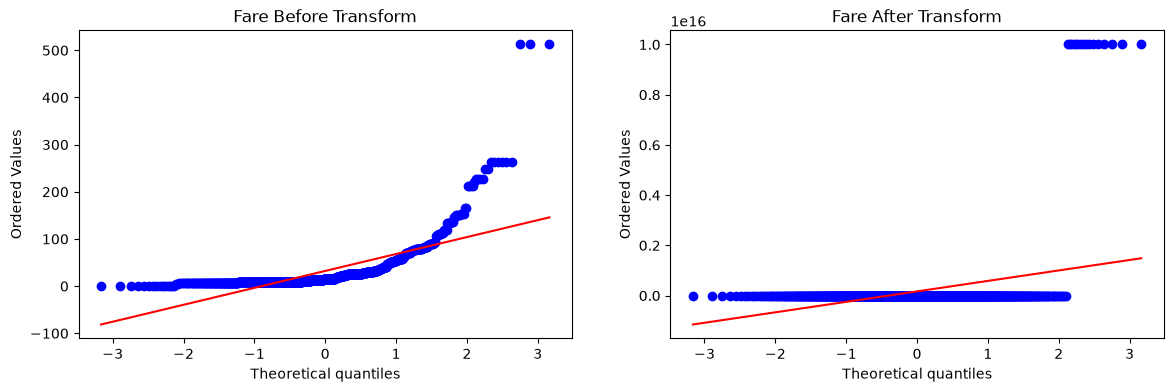

In [131]:
# Apply reciprocal transformation: 1/(x + 0.1), adding 0.1 to the denominator to avoid division by zero
apply_transform(lambda x: 1/(x+0.0000000000000001))

Accuracy 0.6195131086142323


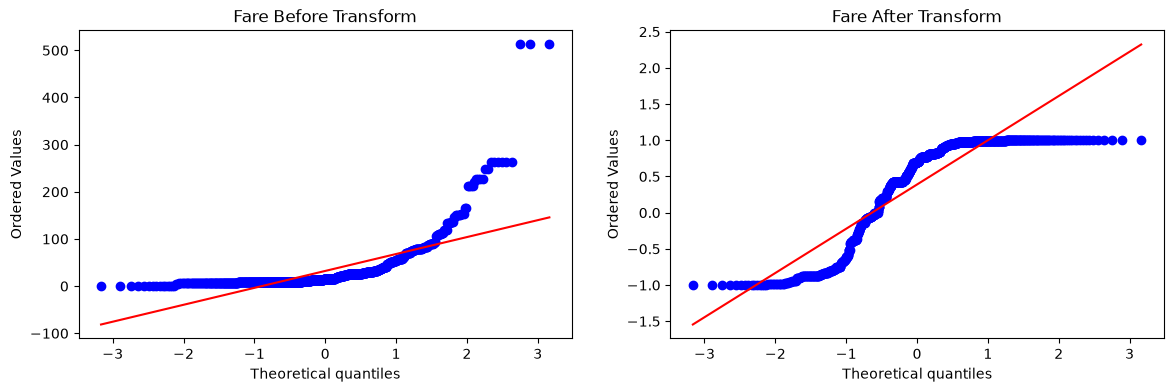

In [132]:
apply_transform(np.sin)